# Visualizations
### Where airport workers live

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from src.config import AIRPORTS, OUTPUT_DIR, PROCESSED_DIR

In [2]:
# FIPS to county mapping
COUNTY_NAMES = {
    "001": "Alameda",
    "013": "Contra Costa",
    "041": "Marin",
    "055": "Napa",
    "075": "San Francisco",
    "081": "San Mateo",
    "085": "Santa Clara",
    "095": "Solano",
    "097": "Sonoma",
}
AIRPORT_COUNTY = {"SFO": "San Mateo", "OAK": "Alameda", "SJC": "Santa Clara"}

In [3]:
def worker_shares_by_county():
    """percent of each airport's bay area workers living in each county, plus worker totals."""
    workers = pd.read_csv(f"{PROCESSED_DIR}/airport_workers_by_tract.csv", dtype={"GEOID": str})
    workers["county"] = workers["GEOID"].str[2:5].map(COUNTY_NAMES)
    # code is airport code
    counts = workers.pivot_table(index="county", columns="code", values="S000", aggfunc="sum", fill_value=0)
    counts = counts.loc[counts.sum(axis=1).sort_values().index]
    # return each county's percent for each airport, total worker ct for each airport from LODES
    return counts.div(counts.sum()) * 100, counts.sum()
worker_shares_by_county()

(code                 OAK        SFO        SJC
 county                                        
 Napa            0.423867   0.592478   0.229768
 Marin           0.945549   1.554182   0.638244
 Sonoma          1.891099   1.322342   1.097779
 Solano          4.336485   3.941267   1.736022
 Contra Costa   15.487447   9.136184   6.152668
 San Francisco   6.847082  20.032629   3.267807
 Santa Clara     7.694816   8.560879  65.892264
 San Mateo       8.346919  35.188047   5.182538
 Alameda        54.026736  19.671990  15.802910,
 code
 OAK     3067
 SFO    11646
 SJC     3917
 dtype: int64)

In [4]:
def plot_worker_home_counties():
    shares, totals = worker_shares_by_county()
    fig, axes = plt.subplots(1, 3, figsize=(11, 4.5), sharey=True, sharex=True)

    for ax, airport in zip(axes, AIRPORTS):
        colors = ["#FDB515" if c == AIRPORT_COUNTY[airport] else "#003262" for c in shares.index]
        ax.barh(shares.index, shares[airport], color=colors)
        ax.set_title(f"{airport} ({totals[airport]:,} Bay Area workers)", fontsize=11)
        ax.set_xlabel("% of airport's Bay Area workers")
        ax.set_xlim(0, 75)
        ax.spines[["top", "right"]].set_visible(False)
        for county in shares[airport].nlargest(3).index:
            ax.text(shares.loc[county, airport] + 1, county, f"{shares.loc[county, airport]:.0f}%", va="center", fontsize=9)

    fig.suptitle("Where airport workers live: OAK and SJC primarily reside locally, SFO from across the region", fontsize=12)
    caption = "Percentage of each airport's Bay Area resident workers by home county (airport county in gold, 2023 LODES Data)"
    fig.text(0.5, 0.01, caption, ha="center", fontsize=9)
    plt.tight_layout(rect=(0, 0.06, 1, 1))
    fig.savefig(f"{OUTPUT_DIR}/airport_worker_home_counties.png", dpi=300)
    return fig

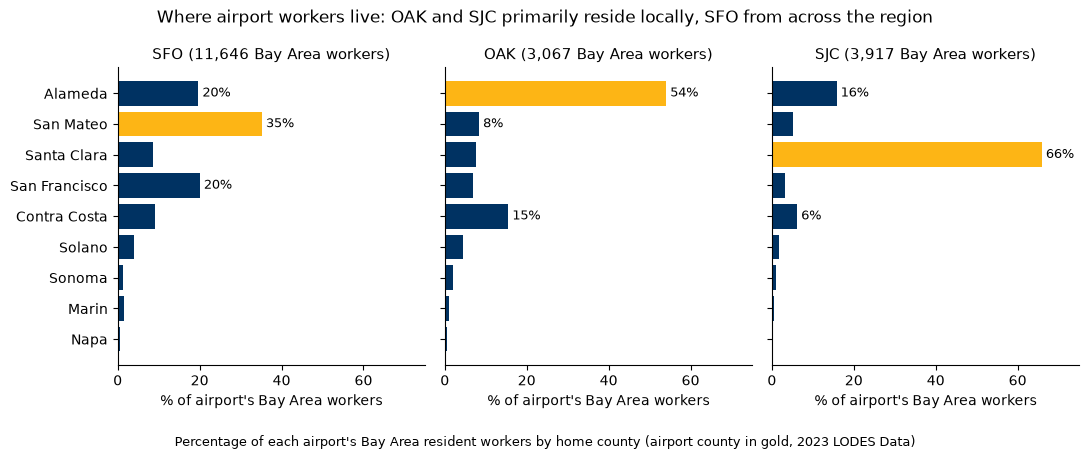

In [5]:
fig = plot_worker_home_counties()